In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.integrate as integrate

#Oppgave a
runs = 100
n = 101
t_steps = 200
h = 1
dt = 1
beta_k = 1
n_runs = 100

k = 1
#V_case = "i"  # "i" eller "ii"

x_min = -200
x_max = 200
x_vals = np.arange(x_min, x_max + 1, dtype=int)


def V(x, case):
    if case == "i":
        return k              
    elif case == "ii":
        return -k * x

def probability(x0, case, beta_k):
    vm = V(x0 - 1, case)
    v0 = V(x0, case)
    vp = V(x0 + 1, case)
    p_p = 1 / (1 + np.exp(-beta_k * (vm - vp)) + np.exp(-beta_k * (v0 - vp)))
    p0  = 1 / (1 + np.exp(-beta_k * (vm - v0)) + np.exp(-beta_k * (vp - v0)))
    p_m = 1 / (1 + np.exp(-beta_k * (vp - vm)) + np.exp(-beta_k * (v0 - vm)))
    return p_p, p0, p_m

def funcA(case, beta_k):
    all_positions = []
    for i in range(runs):
        positions = np.arange(n, dtype=int) - n//2
        for t in range(t_steps):
            new_positions = positions.copy()
            for j in range(n):
                x0 = positions[j]
                p_p, p0, p_m = probability(x0, case, beta_k)

                number = np.random.uniform(0, 1)
                if number <= p_m:
                    new_positions[j] = x0 - 1
                elif number >= 1 - p_p:
                    new_positions[j] = x0 + 1
            positions = new_positions
        all_positions.append(positions.copy())

    all_positions = np.array(all_positions)
    vals, counts = np.unique(all_positions.flatten(), return_counts=True)

    count_map = dict(zip(vals, counts))
    counts_on_xvals = np.array([count_map.get(x, 0) for x in x_vals], dtype=float)

    distribution = counts_on_xvals / (runs * n)
    return distribution

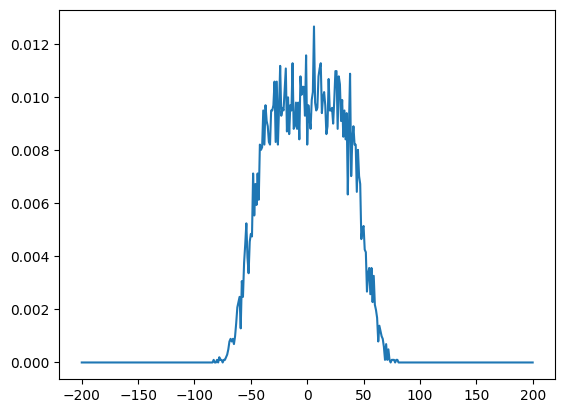

In [2]:
# Oppgave 2a (i)
plt.plot(x_vals, funcA('i', beta_k))
plt.show()


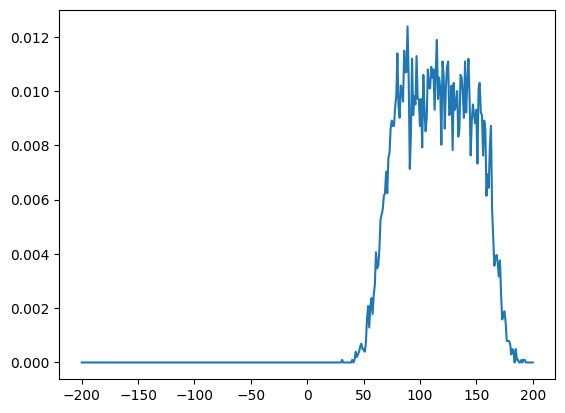

In [3]:
# Oppgave 2a (ii)
plt.plot(x_vals, funcA('ii', beta_k))
plt.show()

In [20]:
#Oppgave b

def funcB(case, beta_k):
    all_positions = []
    for i in range(runs):
        positions = np.arange(n, dtype=int) - n // 2  
        for t in range(t_steps):
            order = np.random.permutation(n)
            occupied = set(positions.tolist())

            for j in order:
                x0 = positions[j]
                p_p, p0, p_m = probability(x0, case, beta_k)

                number = np.random.uniform(0, 1)
                if number <= p_m:
                    x = x0 - 1
                    if x not in occupied:
                        occupied.remove(x0)
                        occupied.add(x)
                        positions[j] = x
                elif number >= 1 - p_p:
                    x = x0 + 1
                    if x not in occupied:
                        occupied.remove(x0)
                        occupied.add(x)
                        positions[j] = x

        all_positions.append(positions.copy())

    all_positions = np.array(all_positions)
    vals, counts = np.unique(all_positions.flatten(), return_counts=True)

    count_map = dict(zip(vals, counts))
    counts_on_xvals = np.array([count_map.get(x, 0) for x in x_vals], dtype=float)

    distribution = counts_on_xvals / (runs * n)
    return distribution

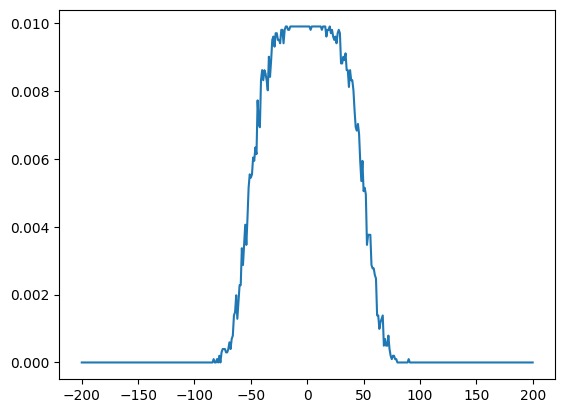

In [5]:
# Oppgave 2b (i)
plt.plot(x_vals, funcB('i', beta_k))
plt.show()

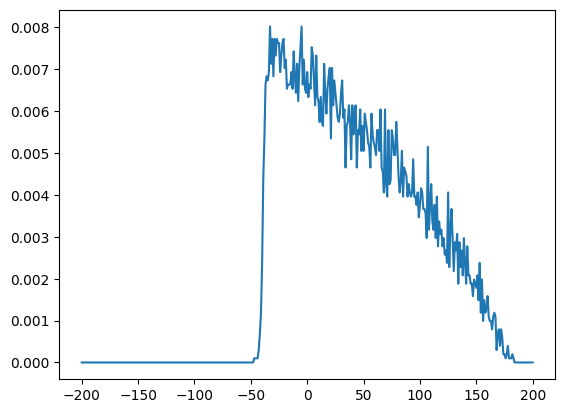

In [6]:
# Oppgave 2b (ii)
plt.plot(x_vals, funcB('ii', beta_k))
plt.show()

/var/folders/c4/x9ppndpx7x506grq5tlht9f00000gn/T/ipykernel_75727/1870697073.py:33: RuntimeWarning: overflow encountered in exp
  p0  = 1 / (1 + np.exp(-beta_k * (vm - v0)) + np.exp(-beta_k * (vp - v0)))
/var/folders/c4/x9ppndpx7x506grq5tlht9f00000gn/T/ipykernel_75727/1870697073.py:34: RuntimeWarning: overflow encountered in exp
  p_m = 1 / (1 + np.exp(-beta_k * (vp - vm)) + np.exp(-beta_k * (v0 - vm)))


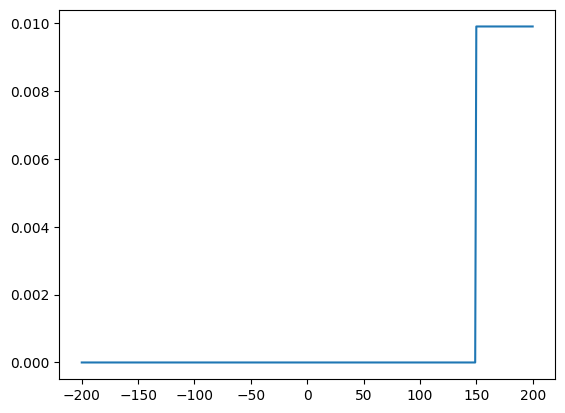

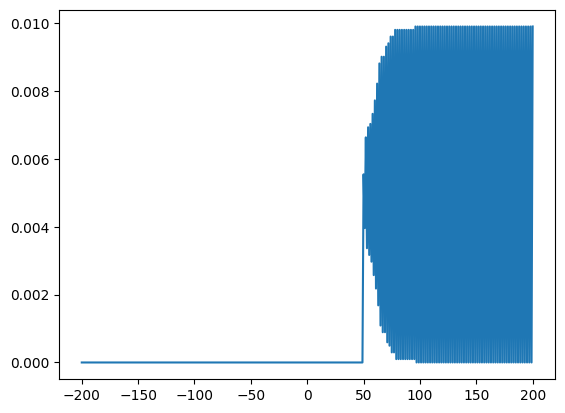

In [7]:
#Oppgave 2c 
beta_k = 1000
plt.plot(x_vals, funcA('ii', beta_k))
plt.show()
plt.plot(x_vals, funcB('ii', beta_k))
plt.show()

In [21]:
#Oppgave 3a
alpha = 0.8
T_p = 500
h = 1
N_x = 100
dt = 1
beta_k = 1000
k = 1
N_p = 12 * N_x

P = 2 * N_x                
T_total = 20 * T_p

np.random.seed(0)

def V1_array(P, N_x, alpha, k):
    x = np.arange(P)
    xmod = x % N_x

    V = np.zeros(P, dtype=float)

    mask1 = (xmod > 0) & (xmod <= alpha * N_x)
    V[mask1] = k * xmod[mask1] / (alpha * N_x)

    mask2 = (xmod > alpha * N_x) & (xmod < N_x)
    V[mask2] = -k * (xmod[mask2] - N_x) / ((1 - alpha) * N_x)

    return V

V1_tab = V1_array(P, N_x, alpha, k)
V2_tab = np.zeros(P, dtype=float)

def step_probs(positions, Vtab, beta_k):
    xm = (positions - 1) % P
    x0 = positions
    xp = (positions + 1) % P

    Em = Vtab[xm]
    E0 = Vtab[x0]
    Ep = Vtab[xp]

    Emin = np.minimum(Em, np.minimum(E0, Ep))
    wm = np.exp(-beta_k * (Em - Emin))
    w0 = np.exp(-beta_k * (E0 - Emin))
    wp = np.exp(-beta_k * (Ep - Emin))
    Z = wm + w0 + wp

    p_m = wm / Z
    p_0 = w0 / Z
    p_p = wp / Z
    return p_m, p_0, p_p

positions = np.arange(N_p, dtype=int) % P

j_current = np.empty(T_total, dtype=float)

for t in range(T_total):
    if (t // T_p) % 2 == 0: 
        p_m = np.full(N_p, 1/3) #?
        p_p = np.full(N_p, 1/3)
    else:
        p_m, p_0, p_p = step_probs(positions, V1_tab, beta_k)

    r = np.random.rand(N_p)

    move_left  = (r <= p_m)
    move_right = (r >= 1 - p_p)

    positions = (positions - move_left.astype(int) + move_right.astype(int)) % P

    n_m = move_left.sum()
    n_p = move_right.sum()
    j_current[t] = (n_p - n_m) / N_p

def j(t):
    return j_current[t]

def j_mean(n):
    a = 2 * T_p * n
    b = 2 * T_p * (n + 1)
    return float(np.mean(j_current[a:b]))

for n in range(10):
    print(n, j_mean(n))

0 -0.029916666666666668
1 -0.012833333333333334
2 -0.01425
3 -0.014166666666666666
4 -0.01375
5 -0.012833333333333332
6 -0.01375
7 -0.013083333333333334
8 -0.014166666666666668
9 -0.01425


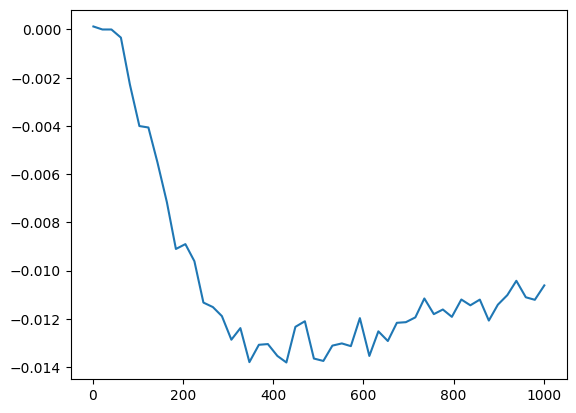

In [22]:
#Oppgave 3b
N_p = 40 * N_x 

Tp_vals = np.linspace(1, 1001, 50, dtype=int)

def run_one_cycle(Tp, rng):
    positions = np.empty(N_p, dtype=int)
    positions[:N_p//2] = 0
    positions[N_p//2:] = N_x

    j_list = []

    for t in range(2 * Tp):
        if t < Tp:
            Vtab = V2_tab
            p_m = np.full(N_p, 1/3)
            p_p = np.full(N_p, 1/3)
        else:
            Vtab = V1_tab
            p_m, _, p_p = step_probs(positions, Vtab, beta_k)

        r = rng.random(N_p)

        move_left  = (r <= p_m)
        move_right = (r >= 1 - p_p)

        positions = (positions - move_left.astype(int) + move_right.astype(int)) % P

        n_m = move_left.sum()
        n_p = move_right.sum()
        j_list.append((n_p - n_m) / N_p)

    return float(np.mean(j_list))

rng = np.random.default_rng(0)  

Javg_list = []
for T_p in Tp_vals:
    Javg = run_one_cycle(T_p, rng)
    Javg_list.append(Javg)
Javg_values = np.array(Javg_list)

plt.figure()
plt.plot(Tp_vals, Javg_values)
plt.show()


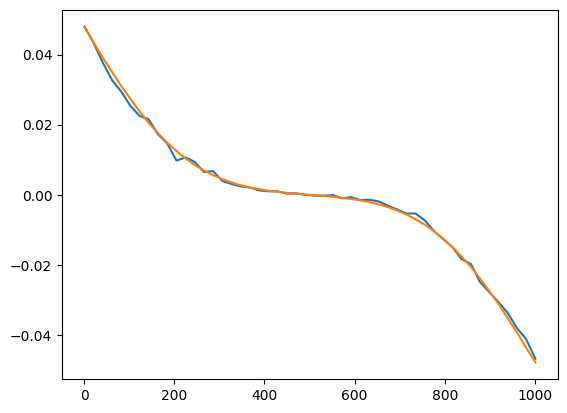

In [23]:
#Oppgave 3c

alpha_arr = np.arange(0.01, 1.0, 0.02)
T_p = 500
N_p = 12 * N_x

rng = np.random.default_rng(0)  

def erfc(x):
    val, err = integrate.quad(lambda t: np.exp(-t**2), x, np.inf)
    return 2 / np.sqrt(np.pi) * val

def analytic_current_mean(alpha, T_p):
    x1 = (alpha * N_x / 2) * np.sqrt(3 / T_p)
    x2 = ((1 - alpha) * N_x / 2) * np.sqrt(3 / T_p)
    return N_x / (4 * T_p) * (erfc(x1) - erfc(x2))

def func_c():
    global V1_tab
    anal_alpha = []
    Javg_list = []
    for alpha in alpha_arr:
        anal_alpha.append(analytic_current_mean(alpha, T_p))

        V1_tab = V1_array(P, N_x, alpha, k) 
        Javg = run_one_cycle(T_p, rng)
        Javg_list.append(Javg)

    return np.array(anal_alpha), np.array(Javg_list)

anal_alpha, Javg_values = func_c()

plt.figure()
plt.plot(Tp_vals, Javg_values)
plt.plot(Tp_vals, anal_alpha)
plt.show()

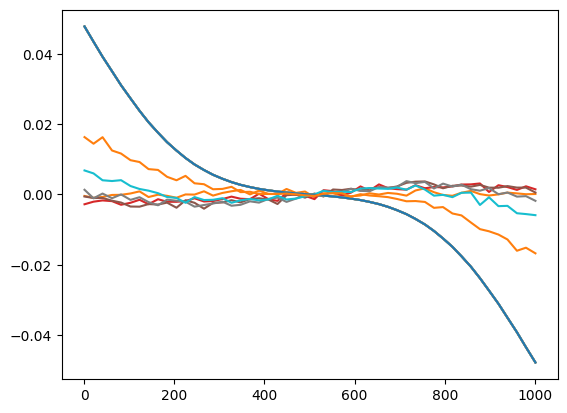

In [24]:
# Oppgave 3d
beta_k_arr = np.array([0.01, 1, 2, 3, 5, 10])

def func_d():
    global beta_k
    a_lst = []
    J_lst = []
    for bk in beta_k_arr:
        beta_k = bk
        anal_alpha, Javg_values = func_c()
        a_lst.append(anal_alpha)
        J_lst.append(Javg_values)
    return np.array(a_lst), np.array(J_lst)

anal_alpha_arr, Javg_values_arr= func_d()

for i in range(6):
    plt.plot(Tp_vals,anal_alpha_arr[i])
    plt.plot(Tp_vals, Javg_values_arr[i])

plt.show()

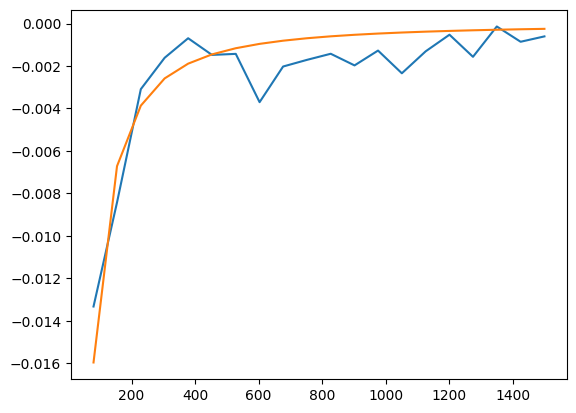

In [25]:
#Oppgave 3e

alpha = 0.8
T_p_vals = np.linspace(80,1500, 20, dtype = int)
rng = np.random.default_rng(0)  
N_x = 10
P = 2 * N_x
N_p = 40 * N_x
V1_tab = V1_array(P, N_x, alpha, k)
V2_tab = np.zeros(P)


def run_one_cycle(T_p, rng):
    positions = np.empty(N_p, dtype=int)
    positions[:N_p//2] = 0
    positions[N_p//2:] = N_x

    j_list = []

    for t in range(2 * T_p):
        if t < T_p:
            Vtab = V2_tab
            p_m = np.full(N_p, 1/3)
            p_p = np.full(N_p, 1/3)
        else:
            Vtab = V1_tab
            p_m, p_0, p_p = step_probs(positions, Vtab, beta_k)

        r = rng.random(N_p)

        move_left  = (r <= p_m)
        move_right = (r >= 1 - p_p)

        positions = (positions - move_left.astype(int) + move_right.astype(int)) % P

        n_m = move_left.sum()
        n_p = move_right.sum()
        j_list.append((n_p - n_m) / N_p)

    return float(np.mean(j_list))

J_avg_list = []
anal_T_p = []
for T_p in T_p_vals:
    J_avg_list.append(run_one_cycle(T_p, rng))
    anal_T_p.append(analytic_current_mean(alpha, T_p))

plt.figure()
plt.plot(T_p_vals, J_avg_list)
plt.plot(T_p_vals, anal_T_p)
plt.show()


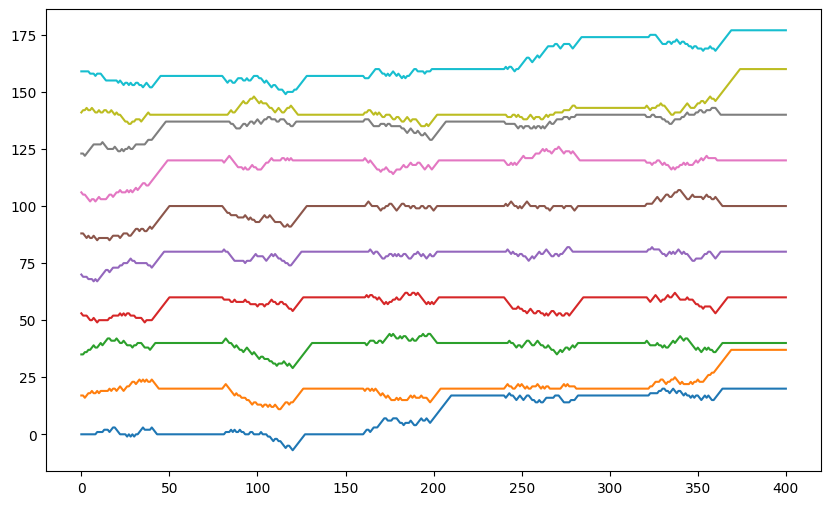

In [30]:
# Oppgave 4a

alpha = 0.2
N_x = 20
P = 2 * N_x
L = 4 * P
Beta_k = 1000
T_p = 40
N_c = 5
t_steps = 2 * N_c * T_p

n_par = 10
b = 3

def build_V1(alpha, N_x):
    limit = int(alpha * N_x)
    n = np.arange(N_x)
    V = np.zeros(N_x, dtype=float)
    left = (n <= limit)
    right = (n > limit)
    V[left] = n[left] / max(limit, 1)
    V[right] = (N_x - n[right]) / max((N_x - limit), 1)
    return np.concatenate([V, V])

V_one = build_V1(alpha, N_x)
V1 = np.tile(V_one, 4)
V2 = np.zeros(L)

x0 = np.linspace(0, L-1, n_par, dtype=int)

def probs_single(V, x0, Beta_k):
    V_l = V[(x0 - 1) % L]
    V_0 = V[x0]
    V_r = V[(x0 + 1) % L]
    p_plus = 1 / (1 + np.exp(-Beta_k*(V_l - V_r)) + np.exp(-Beta_k*(V_0 - V_r)))
    p_0 = 1 / (1 + np.exp(-Beta_k*(V_r - V_0)) + np.exp(-Beta_k*(V_l - V_0)))
    p_minus = 1 / (1 + np.exp(-Beta_k*(V_r - V_l)) + np.exp(-Beta_k*(V_0 - V_l)))
    return p_plus, p_0, p_minus

def hardcore_flash(x0, t_steps, N_p, T_p):
    x = x0.copy().astype(int)
    traj = np.zeros((t_steps + 1, N_p), dtype=int)
    traj[0] = x

    J_list = []
    
    
    for i in range(t_steps):
        off_part = (i % (2 * T_p)) < T_p
        if off_part:
            V = V2
        else:
            V = V1
        
        occupied = set()
        for xi in x:
            for k in range(b):
                occupied.add((xi + k) % L)
            
        order = np.random.permutation(len(x))

        n_m = 0
        n_p = 0

        for j in order:
            if off_part:
                p_plus, p_0, p_minus = 1/3, 1/3, 1/3
            else:
                p_plus, p_0, p_minus = probs_single(V, x[j], Beta_k)
                
            r = np.random.rand()

            if r <= p_minus:
                new_pos = (x[j] - 1) % L
            elif r > (1 - p_plus):
                new_pos = (x[j] + 1) % L
            else:
                continue

            if new_pos == (x[j] + 1) % L:
                new_site = (x[j] + b) % L
                if new_site not in occupied:
                    occupied.discard(x[j])
                    occupied.add(new_site)
                    x[j] = new_pos
                    n_p += 1

            elif new_pos == (x[j] - 1) % L:
                new_site = (x[j] - 1) % L
                if new_site not in occupied:
                    occupied.discard((x[j] + b - 1) % L)
                    occupied.add(new_site)
                    x[j] = new_pos
                    n_m += 1
                    
        traj[i+1] = x.copy()
        J_list.append((n_p - n_m) / N_p)

        
    return traj, np.mean(J_list)

traj, J = hardcore_flash(x0, t_steps, n_par, T_p)

traj_unwrap = traj.copy().astype(int)
for j in range(n_par):
    for t in range(1, t_steps + 1):
        dx = traj[t, j] - traj[t-1, j]
        if dx > L // 2:
            traj_unwrap[t:, j] -= L
        elif dx < -L // 2:
            traj_unwrap[t:, j] += L

plt.figure(figsize=(10,6))
for j in range(n_par):
    plt.plot(np.arange(t_steps + 1), traj_unwrap[:, j])
plt.show()


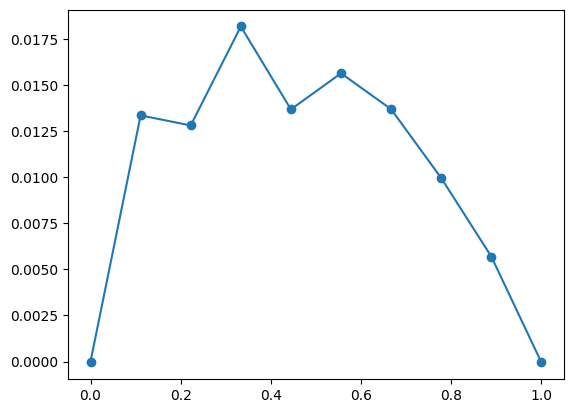

In [31]:
#Oppgave 4b 

N_s = 10
beta_k = 1000
N_x = 100
T_p = 300
alpha = 0.2
b = 20
N_c = 100
t_steps = 2 * N_c * T_p

L = N_x * N_s 

V_one = build_V1(alpha, N_x)
V1 = np.tile(V_one, N_s) 
V2 = np.zeros(L)

p_vals = np.linspace(0,1,10) 
J_vals = []

for p in p_vals:
    if p == 0:
        J_vals.append(0)
        continue

    N_p = int(np.round((p * N_s * N_x) / b))
    N_p = max(N_p, 1)

    x0 = np.linspace(0, L-1, N_p, dtype = int)

    traj, J = hardcore_flash(x0, t_steps, N_p, T_p)
    J_vals.append(J)

J_vals = np.array(J_vals)

plt.plot(p_vals, J_vals, '-o')
plt.show()


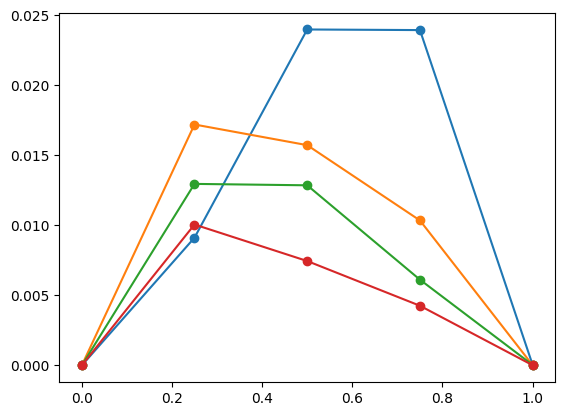

In [ ]:
#Oppgave 4c

N_s = 10
beta_k = 1000
N_x = 100
alpha = 0.2
b = 20

L = N_x * N_s 

V_one = build_V1(alpha, N_x)
V1 = np.tile(V_one, N_s) 
V2 = np.zeros(L)

p_vals = np.linspace(0,1,5) 

T_p_vals = [100,300,500,900]

for T_p in T_p_vals:

    N_c = int(np.round(30000 / T_p))
    t_steps = 2 * N_c * T_p

    J_vals = []
    for p in p_vals:
        if p == 0:
            J_vals.append(0)
            continue

        N_p = int(np.round((p * N_s * N_x) / b))
        N_p = max(N_p, 1)

        x0 = np.linspace(0, L-1, N_p, dtype = int)

        traj, J = hardcore_flash(x0, t_steps, N_p, T_p) 
        J_vals.append(J)

    J_vals = np.array(J_vals)

    plt.plot(p_vals, J_vals, '-o')
plt.show()


